# NFL Game Simulator (Python + nflverse data)

Your original cell ran `install.packages("nflseedR")`, which is **R** code, inside a **Python** kernel, hence the `NameError`. This notebook stays in Python and pulls the same nflverse game data (every game since 1999, updated during the season) straight from GitHub. No R install needed.

**How the model works**
1. **Ratings:** offense and defense rating per team from a weighted ridge regression on points scored, adjusted for opponent and home field. Recent games weigh more; last season is discounted so ratings regress toward average each offseason.
2. **Simulation:** each team's expected points become per-drive TD/FG odds, and each game plays out ~11 drives per team, so final scores land on real NFL numbers (3s, 7s, 10s) instead of smooth decimals.
3. **Monte Carlo:** run the game 20,000 times and read off win %, spread, total, and the most likely final scores.

Run cells top to bottom. To simulate a different game, edit `HOME` and `AWAY` in step 3.

In [1]:
# Only needed the first time
# %pip install pandas numpy matplotlib

## 1. Simulator code

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import numpy as np
import pandas as pd

DATA_URL = "https://github.com/nflverse/nfldata/raw/master/data/games.csv"

# Team relocations/renames so history lines up with current abbreviations
TEAM_FIX = {"OAK": "LV", "SD": "LAC", "STL": "LA", "LAR": "LA"}


def load_games(path=DATA_URL):
    g = pd.read_csv(path, low_memory=False)
    for col in ("home_team", "away_team"):
        g[col] = g[col].replace(TEAM_FIX)
    g["gameday"] = pd.to_datetime(g["gameday"])
    return g


# ----------------------------------------------------------------- ratings
def fit_ratings(games, as_of=None, seasons_back=2, half_life_games=16,
                prior_season_weight=0.6, ridge=2.0):
    """Fit offense/defense/home-field ratings from completed games before `as_of`."""
    done = games.dropna(subset=["home_score", "away_score"]).copy()
    if as_of is not None:
        done = done[done["gameday"] < pd.Timestamp(as_of)]
    last_season = done["season"].max()
    done = done[done["season"] > last_season - seasons_back]

    teams = sorted(set(done["home_team"]) | set(done["away_team"]))
    idx = {t: i for i, t in enumerate(teams)}
    n = len(teams)

    # Recency weight: by week order, with an extra haircut for older seasons
    order = done["gameday"].rank(method="dense")
    age = order.max() - order                       # 0 = most recent week
    w = 0.5 ** (age / half_life_games)
    w *= np.where(done["season"] < last_season, prior_season_weight, 1.0)
    neutral = (done["location"] == "Neutral").to_numpy()

    # Two rows per game: home offense vs away defense, away offense vs home defense
    rows, y, wts = [], [], []
    for (_, gm), wt, neu in zip(done.iterrows(), w, neutral):
        h, a = idx[gm.home_team], idx[gm.away_team]
        for off, dfn, pts, home in ((h, a, gm.home_score, 1), (a, h, gm.away_score, 0)):
            x = np.zeros(2 * n + 1)
            x[off] = 1
            x[n + dfn] = -1
            x[2 * n] = 0 if neu else (0.5 if home else -0.5)
            rows.append(x); y.append(pts); wts.append(wt)

    X, y, W = np.array(rows), np.array(y), np.array(wts)
    mu = np.average(y, weights=W)
    # Weighted ridge (home-field term not penalized)
    P = np.eye(2 * n + 1) * ridge
    P[-1, -1] = 0.0
    beta = np.linalg.solve(X.T @ (W[:, None] * X) + P, X.T @ (W * (y - mu)))

    r = pd.DataFrame({"team": teams, "off": beta[:n], "def": beta[n:2 * n]})
    r["net"] = r["off"] + r["def"]
    return {"ratings": r.set_index("team"), "league_avg": mu,
            "home_edge": beta[-1], "as_of": as_of}


def expected_points(model, home, away, neutral=False):
    r, mu = model["ratings"], model["league_avg"]
    hfa = 0.0 if neutral else model["home_edge"] / 2
    h = mu + r.at[home, "off"] - r.at[away, "def"] + hfa
    a = mu + r.at[away, "off"] - r.at[home, "def"] - hfa
    return max(h, 3.0), max(a, 3.0)


# -------------------------------------------------------------- simulation
def _drive_probs(exp_pts, drives=11.0, fg_per_td=0.75, xp=0.94):
    """Turn expected points into per-drive TD/FG probabilities."""
    td_value = 6 + xp
    p_td = exp_pts / (drives * (td_value + 3 * fg_per_td))
    return min(p_td, 0.6), min(p_td * fg_per_td, 0.35)


def _sim_team(exp_pts, n_sims, rng, drives):
    p_td, p_fg = _drive_probs(exp_pts)
    tds = rng.binomial(drives, p_td)
    fgs = rng.binomial(drives - tds, p_fg / (1 - p_td))
    xps = rng.binomial(tds, 0.94)
    return 6 * tds + xps + 3 * fgs


def simulate_game(model, home, away, n_sims=20000, neutral=False, seed=None):
    """Monte Carlo a single game. Returns a dict of summary stats + raw scores."""
    rng = np.random.default_rng(seed)
    exp_h, exp_a = expected_points(model, home, away, neutral)
    drives = rng.integers(10, 13, size=n_sims)      # shared pace per game
    hs = _sim_team(exp_h, n_sims, rng, drives)
    as_ = _sim_team(exp_a, n_sims, rng, drives)

    # Overtime for ties: rough split weighted toward the better team, ~8% stay tied
    tied = hs == as_
    ot_home_p = np.clip(0.5 + (exp_h - exp_a) / 28, 0.2, 0.8)
    roll = rng.random(n_sims)
    home_ot = tied & (roll < 0.92 * ot_home_p)
    away_ot = tied & (roll >= 0.92 * ot_home_p) & (roll < 0.92)
    hs = hs + np.where(home_ot, 3, 0)
    as_ = as_ + np.where(away_ot, 3, 0)

    margin = hs - as_
    scores = pd.Series(list(zip(hs, as_))).value_counts(normalize=True).head(5)
    return {
        "home": home, "away": away,
        "home_win_pct": float((margin > 0).mean()),
        "away_win_pct": float((margin < 0).mean()),
        "tie_pct": float((margin == 0).mean()),
        "proj_home_pts": float(hs.mean()), "proj_away_pts": float(as_.mean()),
        "proj_spread": float(-margin.mean()),   # Vegas convention: negative = home favored
        "proj_total": float((hs + as_).mean()),
        "top_scores": [(f"{home} {h} - {away} {a}", round(p * 100, 1)) for (h, a), p in scores.items()],
        "home_scores": hs, "away_scores": as_,
    }


def print_game(res):
    h, a = res["home"], res["away"]
    fav = h if res["proj_spread"] < 0 else a
    print(f"{a} @ {h}")
    print(f"  Win prob:   {h} {res['home_win_pct']:.1%} | {a} {res['away_win_pct']:.1%} | tie {res['tie_pct']:.1%}")
    print(f"  Projection: {h} {res['proj_home_pts']:.1f} - {a} {res['proj_away_pts']:.1f}")
    print(f"  Spread:     {fav} -{abs(res['proj_spread']):.1f}   Total: {res['proj_total']:.1f}")
    print("  Most likely finals:", ", ".join(f"{s} ({p}%)" for s, p in res["top_scores"][:3]))


def simulate_week(model, games, season, week, n_sims=10000, seed=0):
    """Simulate every game on a week's slate and compare to the Vegas line."""
    slate = games[(games.season == season) & (games.week == week)]
    out = []
    for _, g in slate.iterrows():
        res = simulate_game(model, g.home_team, g.away_team, n_sims,
                            neutral=(g.location == "Neutral"), seed=seed)
        out.append({
            "matchup": f"{g.away_team} @ {g.home_team}",
            "home_win_pct": round(res["home_win_pct"] * 100, 1),
            "model_line": round(res["proj_spread"], 1),
            "vegas_line": -g.spread_line if pd.notna(g.spread_line) else np.nan,
            "model_total": round(res["proj_total"], 1),
            "vegas_total": g.total_line,
            "final": (f"{g.away_score:.0f}-{g.home_score:.0f}"
                      if pd.notna(g.home_score) else ""),
        })
    return pd.DataFrame(out)


# ---------------------------------------------------------------- backtest
def backtest(games, season, start_week=4, n_sims=4000):
    """Refit ratings before each week and grade predictions against results + Vegas."""
    rows = []
    s = games[(games.season == season) & (games.game_type == "REG")]
    for wk in range(start_week, s.week.max() + 1):
        slate = s[(s.week == wk) & s.home_score.notna()]
        if slate.empty:
            continue
        model = fit_ratings(games, as_of=slate.gameday.min())
        for _, g in slate.iterrows():
            if g.home_team not in model["ratings"].index or g.away_team not in model["ratings"].index:
                continue
            res = simulate_game(model, g.home_team, g.away_team, n_sims,
                                neutral=(g.location == "Neutral"), seed=1)
            p = res["home_win_pct"] + res["tie_pct"] / 2
            won = 1.0 if g.result > 0 else (0.5 if g.result == 0 else 0.0)
            rows.append({"week": wk, "p_home": p, "home_won": won,
                         "model_margin": -res["proj_spread"],
                         "vegas_margin": g.spread_line, "actual_margin": g.result})
    bt = pd.DataFrame(rows)
    decided = bt[bt.home_won != 0.5]
    return bt, {
        "games": len(bt),
        "model_pick_accuracy": ((decided.p_home > 0.5) == (decided.home_won == 1)).mean(),
        "vegas_pick_accuracy": ((decided.vegas_margin > 0) == (decided.home_won == 1)).mean(),
        "model_brier": ((bt.p_home - bt.home_won) ** 2).mean(),
        "model_margin_MAE": (bt.model_margin - bt.actual_margin).abs().mean(),
        "vegas_margin_MAE": (bt.vegas_margin - bt.actual_margin).abs().mean(),
    }


## 2. Load data and build current power ratings
`off` = points above league average the offense scores; `def` = points below average the defense allows; `net` = overall strength in points.

In [2]:
games = load_games(DATA_URL)
model = fit_ratings(games)

print(f"League avg points per team: {model['league_avg']:.1f}   Home-field edge: {model['home_edge']:.1f} pts")
power = model["ratings"].sort_values("net", ascending=False).round(1)
power.index.name = None
power.head(32)

League avg points per team: 22.8   Home-field edge: 1.0 pts


,off,def,net
JAX,5.0,4.9,9.8
SEA,3.6,5.2,8.8
SF,3.8,1.0,4.8
BUF,5.9,-1.4,4.5
LA,3.4,0.7,4.2
MIN,-2.0,6.0,4.0
NE,-1.2,4.5,3.4
KC,0.2,2.9,3.1
CHI,2.8,0.1,2.9
DEN,0.1,2.5,2.6


## 3. Simulate one game
Use team abbreviations (ARI, SF, KC, PHI, ...). Set `NEUTRAL = True` for international or Super Bowl games.

PHI @ CHI
  Win prob:   CHI 60.3% | PHI 39.4% | tie 0.3%
  Projection: CHI 24.1 - PHI 20.7
  Spread:     CHI -3.4   Total: 44.8
  Most likely finals: CHI 20 - PHI 17 (1.0%), CHI 23 - PHI 20 (0.8%), CHI 27 - PHI 24 (0.7%)


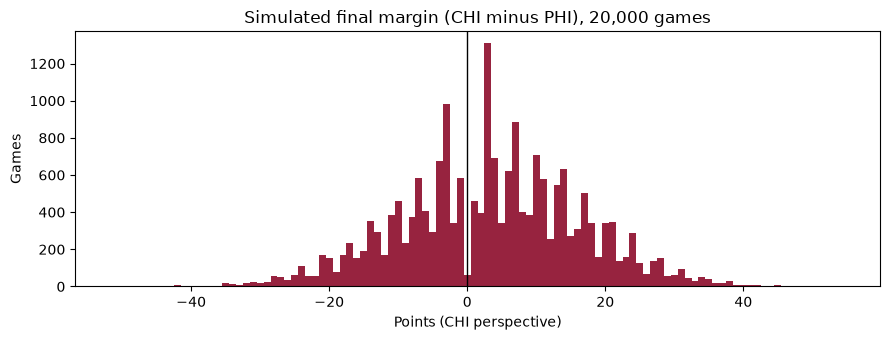

In [5]:
HOME, AWAY, NEUTRAL = "CHI", "PHI", False

result = simulate_game(model, HOME, AWAY, n_sims=20000, neutral=NEUTRAL, seed=42)
print_game(result)

margin = result["home_scores"] - result["away_scores"]
plt.figure(figsize=(9, 3.5))
bins = np.arange(margin.min() - 0.5, margin.max() + 1.5)
plt.hist(margin, bins=bins, color="#97233F")
plt.axvline(0, color="black", lw=1)
plt.title(f"Simulated final margin ({HOME} minus {AWAY}), 20,000 games")
plt.xlabel(f"Points ({HOME} perspective)"); plt.ylabel("Games")
plt.tight_layout(); plt.show()

## 4. Simulate a full week vs. the Vegas lines
Lines use the Vegas convention: negative means the home team is favored. Big gaps between `model_line` and `vegas_line` usually mean the model is missing something (injuries, QB changes, early-season noise), not that you found free money.

In [6]:
SEASON, WEEK = 2026, 3
simulate_week(model, games, SEASON, WEEK)

,matchup,home_win_pct,model_line,vegas_line,model_total,vegas_total,final
0,ATL @ GB,46.9,1.0,-4.5,45.6,43.5,35-14
1,LAC @ BUF,76.8,-9.6,-7.0,46.8,50.5,16-24
2,CAR @ CLE,46.9,1.0,2.5,44.2,41.5,18-21
3,NYJ @ DET,69.5,-6.9,-7.0,51.5,49.5,24-31
4,HOU @ IND,46.6,1.2,1.5,48.1,41.5,17-19
5,NE @ JAX,72.7,-7.5,-3.0,40.3,46.5,6-35
6,KC @ MIA,21.6,9.7,10.0,41.0,45.5,24-10
7,TEN @ NYG,67.5,-5.5,-2.5,36.6,37.5,7-12
8,CIN @ PIT,42.0,2.4,3.5,46.2,42.5,27-30
9,SEA @ WAS,21.2,10.4,8.5,49.0,40.5,31-33


## 5. How good is it? Backtest on 2025
For every week from Week 4 on, ratings are refit using only games played before that week, then graded against actual results and the Vegas closing spread. Vegas is the benchmark to beat; it's very hard to.

In [6]:
bt, stats = backtest(games, 2025, n_sims=4000)
pd.Series(stats).round(3)

games                  224.000
model_pick_accuracy      0.610
vegas_pick_accuracy      0.632
model_brier              0.226
model_margin_MAE        10.398
vegas_margin_MAE         9.924
dtype: float64

## Where to take it next
Ranked by payoff per hour of work:

1. **Blend in the Vegas line.** Averaging the model spread with the market spread usually beats either alone. Cheapest real accuracy gain.
2. **QB adjustment.** `games.csv` has `home_qb_name`/`away_qb_name`. Knock a team's offense down when its starter is out.
3. **Play-by-play efficiency.** Swap points for EPA per play from nflfastR data (`nflverse/nflverse-data` releases). EPA is less noisy than raw scores, so ratings stabilize faster early in the season.
4. **Season simulator.** Loop `simulate_game` over the remaining schedule to get playoff odds. That's what nflseedR does in R.

**If you want the R route instead:** switch the Jupyter kernel to R (install R + `IRkernel`), or use RStudio, then run `install.packages("nflverse")`, `library(nflverse)`, and `nflseedR::simulate_nfl(nfl_season = 2026, simulations = 1000)`. That gives full-season and playoff simulations out of the box, but not the single-game tool built here.